> **中文阅读版**：本文件是 `03_hybrid_retrieval.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 基于倒数排名融合的混合检索

**Docker 镜像**：`ml4t-gpu`

**第 22 章：面向金融研究的 RAG**（第 22.5 节）

在一个由 10-K 段落组成的语料库上构建四套检索栈：BM25、稠密嵌入、通过倒数排名融合（RRF）将二者融合，以及用交叉编码器对该融合结果重排序。

它们排序所依据的分数来自一条词项重叠规则，因为没有人对该语料库进行标注。该规则读取的信号与 BM25 读取的信号相同，而衡量其影响有多大的那一节，在任何排名结果被报告之前就说明了这一点。结论并不是某个检索器胜出，而是不能用一个词法标签规则在词法检索器和语义检索器之间做选择；本 notebook 从内部展示了这种情况是什么样子。

**学习目标**

完成本 notebook 后，你将能够：

- 不借助检索库，根据公式实现 BM25、基于固定版本的编码器实现稠密检索，并对二者实现倒数排名融合。
- 说明倒数排名融合能做到哪些加权分数混合做不到的事，以及当两个检索器使用不同评分尺度时这一点为何重要。
- 度量代理标签规则与依据该规则评分的检索器之间的依赖关系，并识别基准存在这种依赖时的循环性。
- 将 Precision@k 对照其上限（ceiling）来解读，而不是只与某个单一数值比较。
- 说明交叉编码器重排序器（cross-encoder reranker）为何可能在改进排名的同时降低基准分数。

**前置条件**

- SP100 10-K 语料库，通过 `data.load_sec_filings` 读取。[`01_sec_filing_pipeline`](01_sec_filing_pipeline.ipynb) 确立了存储文本的内容；这些段落继承自它。
- `sentence-transformers` 和一块 CUDA GPU。`REQUIRE_GPU` 会拒绝 CPU 运行。
- [`02_domain_embeddings_comparison`](02_domain_embeddings_comparison.ipynb) 构建同类代理标签，并度量其中另一种不同的弱点。

**书中参考**：第 22.5 节，讨论混合检索架构、RRF 推导以及向量数据库选择标准。

## 设置

这些参数控制查询数量和检索深度，使词法、稠密、融合和重排序流水线之间的比较保持可复现。

In [1]:
"""Hybrid Retrieval - BM25 + semantic search with Reciprocal Rank Fusion."""

import re
from collections import defaultdict

import numpy as np
import plotly.graph_objects as go
import polars as pl
import torch

# Visualization
from IPython.display import Markdown, display
from plotly.subplots import make_subplots

# ML4T configuration
from data import load_sec_filings
from utils.reproducibility import set_global_seeds
from utils.style import COLORS, ml4t_palette, show_plotly_with_alt

In [2]:
MAX_QUERIES = 0
MAX_DOCUMENTS = 0
TOP_K = 10
BM25_K1 = 1.5  # how fast repeated terms stop adding score
BM25_B = 0.75  # how much a long document is penalised for its length
RRF_K = 60  # rank offset in the fusion; larger flattens the top of each list
RERANK_CANDIDATES = 50
FINAL_TOP_K = 5
REQUIRE_GPU = True
SEED = 42
# Pinned so a re-run cannot silently change the encoder underneath the scores.
DENSE_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
DENSE_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
CROSS_ENCODER_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
CROSS_ENCODER_REVISION = "c5ee24cb16019beea0893ab7796b1df96625c6b8"

随机种子设置紧跟在参数单元格之后：papermill 的 `SEED` 覆盖必须在使用任何随机性之前生效。

In [3]:
set_global_seeds(SEED)

if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError("This production retrieval benchmark requires a CUDA-capable GPU.")
RETRIEVAL_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dense retrieval device: {RETRIEVAL_DEVICE}")

Dense retrieval device: cuda


In [4]:
print(f"Query cap: {MAX_QUERIES if MAX_QUERIES > 0 else 'all configured queries'}")
print(f"Top-K retrieval: {TOP_K}")

Query cap: all configured queries
Top-K retrieval: 10


`RERANK_CANDIDATES` 是交叉编码器评分的候选池，`FINAL_TOP_K` 是生产流水线按照本章“检索—重排序—生成”模式交给生成阶段的截断数量。单阶段检索器仍在 `TOP_K` 下评估，因此无论生产截断如何，四种方法都在相同深度上评分。

## 1. 语料库与标签

我们从 SP100 语料库加载真实的 10-K 文件文本，并将其切分为可直接用于检索的段落。这些文本块天然包含精确词项（股票代码符号、accession 编号）、概念性内容（风险因素、竞争）以及混合语言——与分析师实际检索文件的方式相符。

`TOP_K` 决定每个检索器有多少空间来呈现已标注文档，因此也决定了下面每个指标的宽容程度。

In [5]:
# Load real 10-K filing chunks from SP100 corpus via the canonical loader
SAMPLE_SYMBOLS = ["AAPL", "MSFT", "AMZN", "JNJ", "BA", "ADBE", "ABT", "AMGN"]
filings_df = (
    load_sec_filings(form_type="10-K", universe="sp100", symbols=SAMPLE_SYMBOLS)
    .sort(["filing_date", "symbol"], descending=[True, False])
    .unique(subset=["symbol"], keep="first")
    .sort("symbol")
)

raw_chunks = []
for row in filings_df.iter_rows(named=True):
    symbol = row["symbol"]
    text = row["text"]
    if not text or len(text) < 200:
        continue
    sentences = [s.strip() for s in text.replace("\n", " ").split(". ") if len(s.strip()) > 40]
    for j in range(0, len(sentences) - 1, 2):
        chunk = ". ".join(sentences[j : j + 2]) + "."
        if 80 < len(chunk) < 600:
            raw_chunks.append({"symbol": symbol, "text": f"[{symbol}] {chunk}"})

print(f"Chunked {len(raw_chunks)} passages from filing corpus")

Chunked 203 passages from filing corpus


### 选择可复现的文档样本

该辅助函数将带种子的采样和稳定的文档 ID 分配与后续的语料库物化步骤隔离开来。

In [6]:
def sample_document_corpus(
    chunks: list[dict], max_documents: int, seed: int
) -> list[dict[str, str]]:
    """Select a seeded corpus and assign stable IDs in source order."""
    rng = np.random.default_rng(seed)
    n_docs = min(max_documents if max_documents > 0 else 200, len(chunks))
    sample_idx = rng.choice(len(chunks), size=n_docs, replace=False)
    return [
        {"id": f"doc_{i + 1:03d}", "text": chunks[idx]["text"], "source": "10k_filing"}
        for i, idx in enumerate(sorted(sample_idx))
    ]

### 物化检索语料库

应用一次带种子的选择器，然后向每种检索方法提供对齐的文本数组和文档 ID 数组。两百个段落足以让两个检索器都有出错的空间，同时又小到交叉编码器推理能在一分钟内完成。

In [7]:
DOCUMENT_CORPUS = sample_document_corpus(raw_chunks, MAX_DOCUMENTS, SEED)

documents = [d["text"] for d in DOCUMENT_CORPUS]
doc_ids = [d["id"] for d in DOCUMENT_CORPUS]

print(f"Document corpus: {len(documents)} documents")

Document corpus: 200 documents


### 标签及其构成

没有人对该语料库进行标注，因此相关性由一条规则定义：统计查询中长度超过三个字符且在文档中出现的词元数量，并将得分最高的三个文档视为相关，若并列则按文档 ID 打破平局。

将这条规则与 BM25 对照阅读，本 notebook 将在下面两节中构建 BM25。BM25 也统计文档中出现的查询词元；它按逆文档频率对其进行加权，并针对文档长度做归一化，而这就是全部差异。标签规则就是一个未加权的 BM25。

因此，即将比较的四个检索器之一，正是给它们打分的东西的一个简化版本。评估之后的一节会度量这有多大价值，而它的价值很大。

In [8]:
def lexical_token_set(text: str) -> set[str]:
    """Return normalized lexical tokens used by the proxy-label contract."""
    return {token for token in re.findall(r"\b\w+\b", text.lower()) if len(token) > 3}

### 按精确词元重叠对文档排序

该选择器使用共享的词元约定和不可变的文档 ID 平局决胜规则，为每个查询最多创建三个代理相关文档。

In [9]:
def find_proxy_docs(query: str, corpus: list[dict]) -> list[str]:
    """Return up to three documents with the highest positive lexical overlap."""
    query_terms = lexical_token_set(query)
    scored = []
    for doc in corpus:
        overlap = len(query_terms & lexical_token_set(doc["text"]))
        if overlap > 0:
            scored.append((overlap, doc["id"]))
    scored.sort(key=lambda item: (-item[0], item[1]))
    return [doc_id for _overlap, doc_id in scored[:3]]

### 构建带标签的查询集

三种查询类型（精确、概念、混合）与其伪相关性标签配对，使每个检索器都能依据相同的代理真值进行评分。

In [10]:
# Test queries grounded in real 10-K filing content
TEST_QUERIES = []
query_specs = [
    # Queries naming a company or a concrete artefact.
    ("How does Apple compete against low-cost competitors?", "exact"),
    ("What intellectual property protections does the company have?", "exact"),
    ("What are the company's product development capabilities?", "exact"),
    ("pharmaceutical products and regulatory requirements", "exact"),
    ("aircraft defense manufacturing operations", "exact"),
    # The same subject matter phrased without a name to key on.
    ("What competitive threats does the company face?", "conceptual"),
    ("How does the company protect against imitation?", "conceptual"),
    ("What risks affect the company's technology strategy?", "conceptual"),
    ("How does the company develop innovative products?", "conceptual"),
    ("What operational challenges exist in manufacturing?", "conceptual"),
    # Keyword-style fragments rather than questions.
    ("company hardware software integration strategy", "mixed"),
    ("customer acquisition costs and retention", "mixed"),
    ("supply chain risk management approach", "mixed"),
    ("regulatory compliance investment requirements", "mixed"),
    ("market share competition pricing pressure", "mixed"),
]

for query, qtype in query_specs:
    relevant = find_proxy_docs(query, DOCUMENT_CORPUS)
    if not relevant:
        raise ValueError(f"No positive lexical overlap for query: {query}")
    TEST_QUERIES.append((query, qtype, relevant))

if MAX_QUERIES > 0:
    TEST_QUERIES = TEST_QUERIES[:MAX_QUERIES]

N_QUERIES = len(TEST_QUERIES)
print(f"Test queries: {N_QUERIES}")

Test queries: 15


这三种语域是关于措辞的设计选择，而不是这里任何东西都会验证的查询属性。这样分组是因为通常的预期是：字面措辞适合 BM25，而释义适合稠密编码器。第 7 节要问的问题正是数字是否支持这一点，而答案是否定的。

## 2. BM25 实现

BM25（Best Matching 25）是一种词袋检索函数，它根据词频和逆文档频率对文档进行排序。

它有两个常量，均在参数单元格中声明：

- `BM25_K1` 决定重复出现的词多快停止增加得分。较低的值意味着第二次出现比第一次的价值小得多。
- `BM25_B` 决定长文档因其长度而受到多大惩罚，从零时的无惩罚到一时的完全按比例惩罚。

In [11]:
def bm25_tokenize(text: str) -> list[str]:
    """Split on word boundaries and lowercase - the token contract BM25 scores on."""
    return re.findall(r"\b\w+\b", text.lower())

### BM25 的语料库统计

一次性预计算词元计数和文档频率，使评分保持简单。

In [12]:
def build_bm25_index(
    documents: list[str],
) -> tuple[list[list[str]], set[str], dict[str, int], list[int], float]:
    """Tokenize the corpus and compute document-frequency statistics."""
    doc_tokens = [bm25_tokenize(doc) for doc in documents]
    vocab: set[str] = set()
    doc_freqs: dict[str, int] = defaultdict(int)
    doc_lens: list[int] = []

    for tokens in doc_tokens:
        doc_lens.append(len(tokens))
        unique_tokens = set(tokens)
        vocab.update(unique_tokens)
        for token in unique_tokens:
            doc_freqs[token] += 1

    avgdl = float(np.mean(doc_lens))
    return doc_tokens, vocab, doc_freqs, doc_lens, avgdl

### BM25 评分

使用标准 BM25 公式，对一个查询在整个语料库上评分，并保持评分机制可见，便于后续调试。

In [13]:
def compute_bm25_scores(
    query: str,
    doc_tokens: list[list[str]],
    doc_freqs: dict[str, int],
    doc_lens: list[int],
    avgdl: float,
    k1: float,
    b: float,
) -> np.ndarray:
    """Score the full corpus for one query using the BM25 formula."""
    query_tokens = bm25_tokenize(query)
    n_docs = len(doc_tokens)
    scores = np.zeros(n_docs)

    for i, tokens in enumerate(doc_tokens):
        doc_len = doc_lens[i]
        term_freqs = defaultdict(int)
        for token in tokens:
            term_freqs[token] += 1

        for q_term in query_tokens:
            df = doc_freqs.get(q_term)
            if df is None:
                continue
            tf = term_freqs[q_term]
            idf = np.log((n_docs - df + 0.5) / (df + 0.5) + 1)
            numerator = tf * (k1 + 1)
            denominator = tf + k1 * (1 - b + b * doc_len / avgdl)
            scores[i] += idf * numerator / denominator

    return scores

### 构建紧凑的展示预览

此辅助函数只截断面向读者的预览。完整段落仍可用于检索评估和下游交叉编码器评分。

In [14]:
def passage_preview(text: str, limit: int = 100) -> str:
    """Return a compact display preview without altering scoring text."""
    suffix = "..." if len(text) > limit else ""
    return text[:limit] + suffix

### 保留完整检索记录

检索结果携带完整评分文本和单独的紧凑预览，因此展示格式不会改变后续模型输入。

In [15]:
def make_retrieval_result(rank: int, doc_id: str, score: float, text: str) -> dict:
    """Keep the full passage for downstream scoring and add a display preview."""
    return {
        "rank": rank,
        "doc_id": doc_id,
        "score": score,
        "text": text,
        "preview": passage_preview(text),
    }

### 封装 BM25 评分原语

该检索器存储语料库统计信息，应用确定性的文档 ID 平局决胜规则，并输出共享的全文结果模式。

In [16]:
class BM25Retriever:
    """BM25 retrieval implementation for exact lexical matching."""

    def __init__(self, documents: list, k1: float = BM25_K1, b: float = BM25_B):
        self.documents = documents
        self.k1 = k1
        self.b = b
        self.doc_tokens, self.vocab, self.doc_freqs, self.doc_lens, self.avgdl = build_bm25_index(
            documents
        )

    def score(self, query: str) -> np.ndarray:
        return compute_bm25_scores(
            query, self.doc_tokens, self.doc_freqs, self.doc_lens, self.avgdl, self.k1, self.b
        )

    def retrieve(self, query: str, top_k: int = 5) -> list:
        scores = self.score(query)
        top_indices = sorted(
            range(len(scores)), key=lambda index: (-float(scores[index]), doc_ids[index])
        )[:top_k]
        return [
            make_retrieval_result(rank + 1, doc_ids[idx], scores[idx], self.documents[idx])
            for rank, idx in enumerate(top_indices)
        ]

In [17]:
# Initialize BM25 retriever
bm25 = BM25Retriever(documents)
print(f"BM25 index built: {len(bm25.vocab)} unique terms")

# Test query
test_result = bm25.retrieve("AAPL revenue Q4 2023", top_k=3)
print("\nBM25 test query: 'AAPL revenue Q4 2023'")
for r in test_result:
    print(f"  {r['rank']}. {r['doc_id']} (score: {r['score']:.3f})")

BM25 index built: 2111 unique terms

BM25 test query: 'AAPL revenue Q4 2023'
  1. doc_121 (score: 6.141)
  2. doc_061 (score: 5.108)
  3. doc_154 (score: 3.612)


语料库中很少包含的词会获得较高的逆文档频率，因此包含该词的查询会把包含它的段落拉到最前面。这正是 BM25 在申报文件中难以被取代的原因：在申报文件中，一个表单编号或一个股票代码往往就是区分正确段落的全部依据。

## 3. 基于嵌入的语义检索

语义搜索使用稠密嵌入来捕捉超越精确关键词匹配的含义。适用于：
- 改述查询
- 概念相似性
- 跨语言检索

In [18]:
def build_semantic_index(documents: list[str], model_name: str) -> tuple[object, np.ndarray]:
    """Create dense document embeddings via sentence-transformers."""
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer(model_name, revision=DENSE_REVISION, device=RETRIEVAL_DEVICE)
    parameter_device = next(model.parameters()).device
    if REQUIRE_GPU and parameter_device.type != "cuda":
        raise RuntimeError(f"Dense encoder parameters are on {parameter_device}, not CUDA.")
    embeddings = model.encode(documents, show_progress_bar=False)
    print(f"Semantic index built: {embeddings.shape}; parameters={parameter_device}")
    return model, embeddings

设备行是一种检查，而非装饰：一个悄悄回退到 CPU 的模型仍然会产生数值，而 `REQUIRE_GPU` 会拒绝这种情况，而不是让运行耗费一小时却无人注意。

### 语义相似度评分

将一个查询嵌入与预计算的语料库嵌入进行比较，使稠密检索器对其相似度分数的形成方式保持透明。

In [19]:
def semantic_similarity_scores(query: str, model, embeddings: np.ndarray) -> np.ndarray:
    """Compute cosine similarity between one query and the embedded corpus."""
    query_embedding = model.encode([query], show_progress_bar=False)[0]
    doc_norms = np.linalg.norm(embeddings, axis=1)
    query_norm = np.linalg.norm(query_embedding)
    return np.dot(embeddings, query_embedding) / (doc_norms * query_norm + 1e-8)

### 语义检索器封装

该封装使 notebook API 与 BM25 保持并行，同时嵌入和评分辅助函数使稠密检索步骤显式化。

In [20]:
class SemanticRetriever:
    """Semantic retrieval using dense embeddings and cosine similarity."""

    def __init__(self, documents: list, model_name: str = DENSE_MODEL):
        self.documents = documents
        self.model_name = model_name
        self.model, self.embeddings = build_semantic_index(documents, model_name)

    def score(self, query: str) -> np.ndarray:
        return semantic_similarity_scores(query, self.model, self.embeddings)

    def retrieve(self, query: str, top_k: int = 5) -> list:
        scores = self.score(query)
        top_indices = sorted(
            range(len(scores)), key=lambda index: (-float(scores[index]), doc_ids[index])
        )[:top_k]
        return [
            make_retrieval_result(rank + 1, doc_ids[idx], scores[idx], self.documents[idx])
            for rank, idx in enumerate(top_indices)
        ]

In [21]:
# Initialize semantic retriever
semantic = SemanticRetriever(documents)

# Test query
test_result = semantic.retrieve("What are the main risks facing the company?", top_k=3)
print("\nSemantic test query: 'What are the main risks facing the company?'")
for r in test_result:
    print(f"  {r['rank']}. {r['doc_id']} (score: {r['score']:.3f})")

Semantic index built: (200, 384); parameters=cuda:0

Semantic test query: 'What are the main risks facing the company?'
  1. doc_029 (score: 0.662)
  2. doc_080 (score: 0.620)
  3. doc_030 (score: 0.602)


稠密检索器返回与查询不共享任何显著词的段落。这是否更好正是评估的目的；它确实不同，而只有两个检索器出现分歧时，融合才值得构建。

## 4. 倒数排名融合（RRF）

RRF 将来自多个检索器的有序列表合并为一个排序。关键公式：

$$\text{RRF}(d) = \sum_{r \in R} \frac{1}{k + \text{rank}_r(d)}$$

其中：
- $R$ 是检索方法集合
- $k$ 是一个常数（通常为 60），用于削弱高排名的影响
- $\text{rank}_r(d)$ 是文档 $d$ 在检索器 $r$ 中的排名

**RRF 的优点：**
- 无需学习融合权重；本 notebook 固定 k=60
- 对分数尺度差异稳健
- 能优雅地处理不重叠的结果

### RRF 评分函数

核心融合算法：对每个文档，将其在所有检索器列表中的排名的倒数求和。常数 $k=60$ 削弱最高排名结果的影响，使融合更稳健。

In [22]:
def reciprocal_rank_fusion(ranked_lists: list[list], k: int = RRF_K) -> list:
    """
    Combine multiple ranked lists using Reciprocal Rank Fusion.

    Args:
        ranked_lists: List of ranked document ID lists [[doc1, doc2, ...], ...]
        k: Smoothing constant (default 60)

    Returns:
        Fused ranking as list of (doc_id, rrf_score) tuples
    """
    rrf_scores = defaultdict(float)

    for ranked_list in ranked_lists:
        for rank, doc_id in enumerate(ranked_list, 1):
            rrf_scores[doc_id] += 1.0 / (k + rank)

    sorted_docs = sorted(rrf_scores.items(), key=lambda item: (-item[1], item[0]))
    return sorted_docs

### 混合检索器

通过同时运行 BM25 和语义检索，然后经由 RRF 融合它们的有序列表，将两者结合起来。每个检索器获取 `2 * top_k` 个候选，以确保有足够重叠用于有意义的融合。

In [23]:
def format_fused_results(fused: list[tuple[str, float]], top_k: int) -> list:
    """Attach full scoring text and separate previews to fused identities."""
    results = []
    for doc_id, rrf_score in fused[:top_k]:
        doc_idx = doc_ids.index(doc_id)
        results.append(
            make_retrieval_result(
                len(results) + 1,
                doc_id,
                rrf_score,
                documents[doc_idx],
            )
        )
    return results

### 合并词法排名和语义排名

混合检索器在同一语料库上运行两种第一阶段方法，并对它们有序的文档标识应用固定 k 的倒数排名融合。

In [24]:
class HybridRetriever:
    """
    Hybrid retrieval combining BM25 and semantic search with RRF.
    """

    def __init__(
        self,
        bm25_retriever: BM25Retriever,
        semantic_retriever: SemanticRetriever,
        rrf_k: int = RRF_K,
    ):
        self.bm25 = bm25_retriever
        self.semantic = semantic_retriever
        self.rrf_k = rrf_k

    def retrieve(self, query: str, top_k: int = 5) -> list:
        """
        Retrieve using hybrid RRF fusion.
        """
        # Get rankings from both retrievers
        bm25_results = self.bm25.retrieve(query, top_k=top_k * 2)
        semantic_results = self.semantic.retrieve(query, top_k=top_k * 2)

        # Extract ranked doc IDs
        bm25_ranking = [r["doc_id"] for r in bm25_results]
        semantic_ranking = [r["doc_id"] for r in semantic_results]

        # Apply RRF
        fused = reciprocal_rank_fusion([bm25_ranking, semantic_ranking], k=self.rrf_k)
        return format_fused_results(fused, top_k)

In [25]:
# Initialize hybrid retriever
hybrid = HybridRetriever(bm25, semantic)

# Test query - should benefit from both methods
test_result = hybrid.retrieve("Apple supply chain concentration Asia", top_k=3)
print("\nHybrid test query: 'Apple supply chain concentration Asia'")
for r in test_result:
    print(f"  {r['rank']}. {r['doc_id']} (score: {r['score']:.4f})")


Hybrid test query: 'Apple supply chain concentration Asia'
  1. doc_031 (score: 0.0325)
  2. doc_019 (score: 0.0164)
  3. doc_004 (score: 0.0161)


融合后的分数很小且彼此接近，这正是这种构造的关键：RRF 从不查看任一检索器的分数，只看排名，因此个位数的 BM25 分数和小于 1 的余弦相似度从相同位置贡献相同的量。无需进行任何校准，任一检索器也无法通过使用更大的尺度来主导融合。

## 5. 对候选集重排序

RRF 是一种强大的第一阶段融合方法，但 top-k 列表仍可能混合相关段落和边缘相关段落。第二阶段重排序器将查询和每个候选段落一起输入，然后对它们进行细粒度相关性打分。在生产环境中，这通常是 cross-encoder；这里我们在可用时使用它，否则回退到确定性的词汇-语义代理。

### Cross-Encoder 风格重排序器

重排序器接收混合候选列表，并使用以下任一方式重新排序：
- sentence-transformers cross-encoder，或
- 回退评分规则，奖励查询词覆盖、精确数值匹配，以及在第一阶段已经排名靠前的候选段落。

In [26]:
def reranker_tokenize(text: str) -> list[str]:
    """Token contract for the heuristic fallback score."""
    return re.findall(r"\b\w+\b", text.lower())

### 可选的 cross-encoder 后端

优先使用真实的 cross-encoder（如果可用），否则回退到确定性启发式方法，以便 notebook 仍可运行。


In [27]:
def load_cross_encoder(model_name: str):
    """Load a cross-encoder reranker. Falls back to a deterministic heuristic
    only when sentence-transformers is missing - model-loading failures
    raise so the user sees them rather than silently degrading."""
    try:
        from sentence_transformers import CrossEncoder
    except ImportError:
        print("Re-ranker backend: heuristic fallback (sentence-transformers missing)")
        return None, "heuristic"

    model = CrossEncoder(model_name, revision=CROSS_ENCODER_REVISION, device=RETRIEVAL_DEVICE)
    parameter_device = next(model.model.parameters()).device
    if REQUIRE_GPU and parameter_device.type != "cuda":
        raise RuntimeError(f"Cross-encoder parameters are on {parameter_device}, not CUDA.")
    print(f"Re-ranker backend: cross_encoder ({model_name}); parameters={parameter_device}")
    return model, "cross_encoder"


# The heuristic path exists so the notebook is readable without the model, and
# the cell that builds the reranker raises if it is taken, so no number in this
# notebook can come from it.

### 启发式回退分数

奖励查询词重叠、精确数值匹配以及更好的第一阶段排名，使回退方法仍能近似重排序器试图学习的内容。


In [28]:
def heuristic_rerank_score(query: str, candidate: dict) -> float:
    query_tokens = reranker_tokenize(query)
    doc_tokens = reranker_tokenize(candidate["text"])
    if not query_tokens:
        return 0.0

    overlap = len(set(query_tokens) & set(doc_tokens)) / len(set(query_tokens))
    numeric_bonus = sum(
        0.1 for token in query_tokens if any(ch.isdigit() for ch in token) and token in doc_tokens
    )
    rank_bonus = 1.0 / (candidate["rank"] + 1)
    return overlap + numeric_bonus + 0.15 * rank_bonus

### 重排序封装器

该类在真实 cross-encoder 和确定性启发式方法之间进行选择，然后为下游评估规范化候选格式。


In [29]:
class CrossEncoderReranker:
    """Re-rank retrieved candidates with a cross-encoder when available."""

    def __init__(self, model_name: str = CROSS_ENCODER_MODEL):
        self.model_name = model_name
        self.model, self.backend = load_cross_encoder(model_name)

    def rerank(self, query: str, candidates: list[dict], top_k: int = 5) -> list[dict]:
        if not candidates:
            return []

        if self.model is not None:
            pairs = [(query, c["text"]) for c in candidates]
            scores = self.model.predict(pairs)
        else:
            scores = [heuristic_rerank_score(query, c) for c in candidates]

        reranked = [
            {
                "doc_id": candidate["doc_id"],
                "score": float(score),
                "text": candidate["text"],
                "preview": candidate["preview"],
                "first_stage_rank": candidate["rank"],
            }
            for candidate, score in zip(candidates, scores, strict=True)
        ]
        reranked.sort(key=lambda item: (-item["score"], item["doc_id"]))
        return [
            {
                "rank": idx + 1,
                "doc_id": candidate["doc_id"],
                "score": candidate["score"],
                "text": candidate["text"],
                "preview": candidate["preview"],
            }
            for idx, candidate in enumerate(reranked[:top_k])
        ]

### 两阶段检索器

该封装器遵循 §22.5 的模式：混合检索收集一个包含 `n_candidates` 的广泛候选池（默认 `RERANK_CANDIDATES=50`），重排序器对每个查询-候选对打分，并且只返回最终的 top-k。生产环境会将 `FINAL_TOP_K=5` 个 chunk 传给 LLM，而下文的对比评估会对同一个 50 候选池重新排序，并报告 top-`TOP_K` 截断，以便四种方法都在相同深度上评分。

In [30]:
class TwoStageRetriever:
    """Hybrid retrieval followed by cross-encoder-style reranking."""

    def __init__(
        self,
        base_retriever: HybridRetriever,
        reranker: CrossEncoderReranker,
        n_candidates: int = 50,
    ):
        self.base_retriever = base_retriever
        self.reranker = reranker
        self.n_candidates = n_candidates

    def retrieve(self, query: str, top_k: int = 5) -> list[dict]:
        candidates = self.base_retriever.retrieve(query, top_k=self.n_candidates)
        return self.reranker.rerank(query, candidates, top_k=top_k)

In [31]:
reranker = CrossEncoderReranker()
if reranker.backend != "cross_encoder":
    raise RuntimeError("Production completeness requires the cross-encoder reranker.")
two_stage = TwoStageRetriever(hybrid, reranker, n_candidates=RERANK_CANDIDATES)

# Production cut: 50-candidate pool reranked down to FINAL_TOP_K chunks.
test_result = two_stage.retrieve("Apple supply chain concentration Asia", top_k=FINAL_TOP_K)
print("\nTwo-stage test query: 'Apple supply chain concentration Asia'")
print(f"(rerank pool={RERANK_CANDIDATES}, final cut={FINAL_TOP_K})")
for r in test_result:
    print(f"  {r['rank']}. {r['doc_id']} (score: {r['score']:.4f})")

Re-ranker backend: cross_encoder (cross-encoder/ms-marco-MiniLM-L-6-v2); parameters=cuda:0

Two-stage test query: 'Apple supply chain concentration Asia'
(rerank pool=50, final cut=5)
  1. doc_031 (score: -7.0010)
  2. doc_175 (score: -10.6174)
  3. doc_074 (score: -10.6484)
  4. doc_004 (score: -10.6542)
  5. doc_019 (score: -10.7426)


cross-encoder 将查询和段落一起读取，这是 bi-encoder 无法做到的：embedding 对每个文档只计算一次，且不参考查询。代价是它无法预先计算，因此它在 50 个候选上运行，而不是在整个语料库上运行。

## 6. 对比评估

我们使用上文定义的词汇代理标签，评估三种第一阶段检索方法以及增加重排序的两阶段检索器。由于标签是按词项重叠而非人工判断选择的，因此该比较是一种机制诊断，而不是生产证据。在部署前，每个候选都应重新对照人工标签进行测试。

### 三个指标，以及其中一个指标的上限

Precision@k 是 k 个检索到的文档中带有标签的比例。每个查询最多有三个标签，而 `TOP_K` 为十，因此无论检索效果多好，precision 都不能超过十分之三。Recall 和 MRR 都能达到一。请结合结果部分打印的该上限来阅读 precision 列，并优先考虑另外两个指标。

In [32]:
def evaluate_retriever(retriever, queries: list, top_k: int = 5) -> pl.DataFrame:
    """Score a retriever against the proxy labels: Precision@k, recall and MRR per query."""
    results = []

    for query, query_type, relevant_docs in queries:
        retrieved = retriever.retrieve(query, top_k=top_k)
        retrieved_ids = [r["doc_id"] for r in retrieved]

        # Compute metrics
        hits_at_k = len(set(retrieved_ids) & set(relevant_docs))
        precision = hits_at_k / top_k
        recall = hits_at_k / len(relevant_docs) if relevant_docs else 0

        # MRR - reciprocal rank of first relevant result
        mrr = 0.0
        for rank, doc_id in enumerate(retrieved_ids, 1):
            if doc_id in relevant_docs:
                mrr = 1.0 / rank
                break

        results.append(
            {
                "query": query[:40] + "..." if len(query) > 40 else query,
                "query_type": query_type,
                "precision": precision,
                "recall": recall,
                "mrr": mrr,
                "hits": hits_at_k,
            }
        )

    return pl.DataFrame(results)

In [33]:
print("=== Evaluating Retrieval Methods ===\n")

# Evaluate each method
bm25_results = evaluate_retriever(bm25, TEST_QUERIES, top_k=TOP_K)
bm25_results = bm25_results.with_columns(pl.lit("BM25").alias("method"))

semantic_results = evaluate_retriever(semantic, TEST_QUERIES, top_k=TOP_K)
semantic_results = semantic_results.with_columns(pl.lit("Semantic").alias("method"))

hybrid_results = evaluate_retriever(hybrid, TEST_QUERIES, top_k=TOP_K)
hybrid_results = hybrid_results.with_columns(pl.lit("Hybrid (RRF)").alias("method"))

two_stage_results = evaluate_retriever(two_stage, TEST_QUERIES, top_k=TOP_K)
two_stage_results = two_stage_results.with_columns(pl.lit("Hybrid + Rerank").alias("method"))

# Combine results
all_results = pl.concat([bm25_results, semantic_results, hybrid_results, two_stage_results])

=== Evaluating Retrieval Methods ===



## 7. 结果，以及标签规则对它们的影响

In [34]:
# Overall comparison
overall = (
    all_results.group_by("method")
    .agg(
        pl.col("precision").mean().alias("avg_precision"),
        pl.col("recall").mean().alias("avg_recall"),
        pl.col("mrr").mean().alias("avg_mrr"),
    )
    .sort(["avg_mrr", "method"], descending=[True, False])
)

print("=== Overall Performance ===\n")
overall

=== Overall Performance ===



method,avg_precision,avg_recall,avg_mrr
str,f64,f64,f64
"""Hybrid (RRF)""",0.22,0.733333,0.877778
"""BM25""",0.26,0.866667,0.818889
"""Hybrid + Rerank""",0.246667,0.822222,0.638889
"""Semantic""",0.16,0.533333,0.462222


In [35]:
best_proxy_row = overall.row(0, named=True)
proxy_mrr = dict(zip(overall["method"], overall["avg_mrr"], strict=True))
proxy_precision = dict(zip(overall["method"], overall["avg_precision"], strict=True))
# A query with fewer labels than TOP_K cannot fill the cut, and one with more
# labels than TOP_K cannot exceed 1. Average the per-query ceiling rather than
# assuming three labels against a cut of ten.
precision_ceiling = float(
    np.mean([min(len(relevant), TOP_K) / TOP_K for _, _, relevant in TEST_QUERIES])
)
display(
    Markdown(f"""
The highest agreement with the label rule is **{best_proxy_row["method"]}** at an MRR of
{best_proxy_row["avg_mrr"]:.3f}. Adding the cross-encoder to that pipeline takes it to
{proxy_mrr["Hybrid + Rerank"]:.3f}, a fall of
{(proxy_mrr["Hybrid (RRF)"] - proxy_mrr["Hybrid + Rerank"]) / proxy_mrr["Hybrid (RRF)"]:.0%}.
The dense retriever on its own reaches {proxy_mrr["Semantic"]:.3f}.

Every precision figure in the table above is against a ceiling of
{precision_ceiling:.2f} rather than 1, because a query carries at most
{max(len(relevant) for _, _, relevant in TEST_QUERIES)} labels against a cut of {TOP_K}:
{best_proxy_row["method"]} at {proxy_precision[best_proxy_row["method"]]:.2f} is
{proxy_precision[best_proxy_row["method"]] / precision_ceiling:.0%} of what is reachable.
The next section is about why the ordering here should not be read as a ranking of
retrievers.
""")
)


The highest agreement with the label rule is **Hybrid (RRF)** at an MRR of
0.878. Adding the cross-encoder to that pipeline takes it to
0.639, a fall of
27%.
The dense retriever on its own reaches 0.462.

Every precision figure in the table above is against a ceiling of
0.30 rather than 1, because a query carries at most
3 labels against a cut of 10:
Hybrid (RRF) at 0.22 is
73% of what is reachable.
The next section is about why the ordering here should not be read as a ranking of
retrievers.


In [36]:
# Breakdown by query type
by_type = (
    all_results.group_by(["method", "query_type"])
    .agg(
        pl.col("precision").mean().alias("avg_precision"),
        pl.col("mrr").mean().alias("avg_mrr"),
    )
    .sort(["query_type", "avg_mrr", "method"], descending=[False, True, False])
)

print("\n=== Performance by Query Type ===\n")
by_type


=== Performance by Query Type ===



method,query_type,avg_precision,avg_mrr
str,str,f64,f64
"""BM25""","""conceptual""",0.26,1.0
"""Hybrid (RRF)""","""conceptual""",0.24,1.0
"""Hybrid + Rerank""","""conceptual""",0.22,0.733333
"""Semantic""","""conceptual""",0.18,0.64
"""Hybrid (RRF)""","""exact""",0.22,0.833333
…,…,…,…
"""Semantic""","""exact""",0.18,0.366667
"""BM25""","""mixed""",0.24,0.866667
"""Hybrid (RRF)""","""mixed""",0.2,0.8


### 标签规则读取的是 BM25 的信号

该评估对四个检索器进行排名。其中一个检索器 BM25 通过共享查询 token 的加权计数为文档打分；标签规则则通过相同 token 的未加权计数为文档打分。如果二者高度一致，那么 BM25 在该表中的位置衡量的是它与该规则的相似程度，而与检索本身无关。

下面的单元格直接衡量这种一致性：对于每个查询，它对整个语料库进行两次排名，一次按标签规则的重叠计数，一次按 BM25 的分数，并取两个排序之间的 Spearman 相关系数。密集检索器的相同相关系数作为对照。

In [37]:
def spearman(a: np.ndarray, b: np.ndarray) -> float:
    """Rank correlation, ties averaged - both scores are heavily tied at zero."""
    ranked = [pl.Series(values).rank(method="average").to_numpy() for values in (a, b)]
    centred = [values - values.mean() for values in ranked]
    denominator = np.sqrt((centred[0] ** 2).sum() * (centred[1] ** 2).sum())
    return float((centred[0] * centred[1]).sum() / denominator) if denominator else 0.0


label_overlap = {
    query: np.array(
        [len(lexical_token_set(query) & lexical_token_set(doc["text"])) for doc in DOCUMENT_CORPUS]
    )
    for query, _, _ in TEST_QUERIES
}
agreement = pl.DataFrame(
    {
        "query_type": [t for _, t, _ in TEST_QUERIES],
        "bm25_vs_labels": [spearman(label_overlap[q], bm25.score(q)) for q, _, _ in TEST_QUERIES],
        "dense_vs_labels": [
            spearman(label_overlap[q], semantic.score(q)) for q, _, _ in TEST_QUERIES
        ],
    }
)
agreement_summary = agreement.group_by("query_type").agg(
    pl.col("bm25_vs_labels").mean().round(3),
    pl.col("dense_vs_labels").mean().round(3),
)
agreement_summary

query_type,bm25_vs_labels,dense_vs_labels
str,f64,f64
"""exact""",0.884,0.387
"""mixed""",0.897,0.356
"""conceptual""",0.749,0.424


In [38]:
bm25_agreement = float(agreement["bm25_vs_labels"].mean())
dense_agreement = float(agreement["dense_vs_labels"].mean())
total_labels = int(sum(len(relevant) for _, _, relevant in TEST_QUERIES))
hits_by_method = dict(
    all_results.group_by("method").agg(pl.col("hits").sum()).iter_rows()  # noqa: B905
)
rerank_hits = hits_by_method["Hybrid + Rerank"]
fusion_hits = hits_by_method["Hybrid (RRF)"]
if rerank_hits > fusion_hits:
    rerank_vs_fusion = "it finds more of them, and the MRR above says it ranks them lower"
elif rerank_hits < fusion_hits:
    rerank_vs_fusion = "it finds fewer of them, and ranks those it finds lower"
else:
    rerank_vs_fusion = (
        "it finds the same number, and the MRR above differs anyway - which can come from "
        "the ordering, from a different spread of hits across the queries, or from both"
    )
conceptual_bm25 = float(
    by_type.filter((pl.col("method") == "BM25") & (pl.col("query_type") == "conceptual"))[
        "avg_mrr"
    ][0]
)
exact_bm25 = float(
    by_type.filter((pl.col("method") == "BM25") & (pl.col("query_type") == "exact"))["avg_mrr"][0]
)

display(
    Markdown(f"""
Averaged over the {N_QUERIES} queries, BM25's document ordering correlates with the label
rule's at **{bm25_agreement:.2f}**. The dense retriever's correlates at
**{dense_agreement:.2f}**.

That is the benchmark, not a property of the retrievers. BM25 is being scored against a
coarser version of itself, and the dense encoder is being scored against a rule that ignores
everything it was trained to represent.

Two consequences are visible in the table above, and both run against what the query
registers were set up to show. BM25 reaches an MRR of **{conceptual_bm25:.2f}** on the
register named for paraphrase and **{exact_bm25:.2f}** on the one named for literal
matching - the opposite ordering to the one the names imply. And the cross-encoder, the only
component here trained on human relevance judgments, is the component the benchmark
penalises most heavily. Neither is a finding about retrieval. Both are the label rule
showing through.

What the reranker does is visible in the recall column rather than in MRR. It retrieves
**{rerank_hits}** of the {total_labels} labelled documents inside the top {TOP_K} against the
fusion's **{fusion_hits}**: {rerank_vs_fusion}. Reordering by one notion of relevance and
scoring by another separates the two columns like this whenever the two notions differ.
""")
)


Averaged over the 15 queries, BM25's document ordering correlates with the label
rule's at **0.84**. The dense retriever's correlates at
**0.39**.

That is the benchmark, not a property of the retrievers. BM25 is being scored against a
coarser version of itself, and the dense encoder is being scored against a rule that ignores
everything it was trained to represent.

Two consequences are visible in the table above, and both run against what the query
registers were set up to show. BM25 reaches an MRR of **1.00** on the
register named for paraphrase and **0.59** on the one named for literal
matching - the opposite ordering to the one the names imply. And the cross-encoder, the only
component here trained on human relevance judgments, is the component the benchmark
penalises most heavily. Neither is a finding about retrieval. Both are the label rule
showing through.

What the reranker does is visible in the recall column rather than in MRR. It retrieves
**37** of the 45 labelled documents inside the top 10 against the
fusion's **33**: it finds more of them, and the MRR above says it ranks them lower. Reordering by one notion of relevance and
scoring by another separates the two columns like this whenever the two notions differ.


## 8. 四种方法的图表

相同的 MRR 数值，包括整体结果和按查询 register 拆分的结果。两个面板的纵轴都到 1，因为这是 MRR 能达到的尺度，并且方法颜色在两个面板间共享，以便跟踪同一方法从一张图到另一张图。

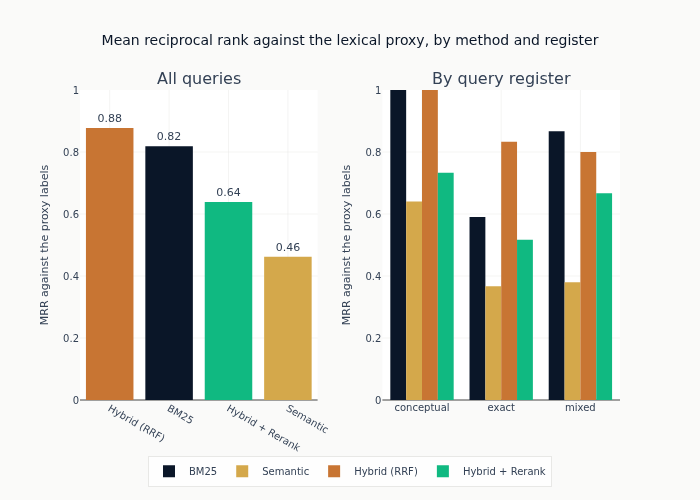

In [39]:
method_order = ["BM25", "Semantic", "Hybrid (RRF)", "Hybrid + Rerank"]
colors = dict(zip(method_order, ml4t_palette(len(method_order), categorical=True), strict=True))

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("All queries", "By query register"),
    horizontal_spacing=0.12,
)
fig.add_trace(
    go.Bar(
        x=overall["method"].to_list(),
        y=overall["avg_mrr"].to_list(),
        marker_color=[colors[m] for m in overall["method"]],
        text=[f"{v:.2f}" for v in overall["avg_mrr"]],
        textposition="outside",
        showlegend=False,
    ),
    row=1,
    col=1,
)
for method in method_order:
    subset = by_type.filter(pl.col("method") == method).sort("query_type")
    fig.add_trace(
        go.Bar(
            name=method,
            x=subset["query_type"].to_list(),
            y=subset["avg_mrr"].to_list(),
            marker_color=colors[method],
        ),
        row=1,
        col=2,
    )

fig.update_layout(
    title="Mean reciprocal rank against the lexical proxy, by method and register",
    height=500,
    showlegend=True,
    legend=dict(orientation="h", yanchor="top", y=-0.18, xanchor="center", x=0.5),
    barmode="group",
    margin=dict(t=90, b=100),
)
fig.update_yaxes(title_text="MRR against the proxy labels", range=[0, 1], row=1, col=1)
fig.update_yaxes(title_text="MRR against the proxy labels", range=[0, 1], row=1, col=2)
show_plotly_with_alt(
    fig,
    "Two bar panels on a mean-reciprocal-rank scale running from zero to one. Left, over all "
    "queries: the RRF fusion stands highest, BM25 just below it, the reranked pipeline well "
    "below that, and the dense retriever lowest. Right, the same four methods grouped by "
    "register: on the conceptual register BM25 and the fusion both reach the top of the axis; "
    "on the exact register every method falls, BM25 furthest, leaving the fusion highest; on "
    "the mixed register BM25 and the fusion stand close together above the other two. The "
    "dense retriever is the lowest bar in all three groups.",
)

左侧面板是上一节解释过的排序：最接近标签规则的两个检索器排得最高，而 cross-encoder 流水线排在其重排序的融合方法之下。右侧面板是相同的排序，但按 register 逐一展示，正是在这里，register 名称不再描述它们被命名的依据。

## 9. 查询增强：HyDE

**假设性文档嵌入（Hypothetical Document Embeddings, HyDE）** 使用 LLM 生成对查询的假设性答案，然后嵌入该答案而非原始查询。
这弥合了分析师表述问题的方式与文档表达同一信息的方式之间的词汇鸿沟。

**HyDE 工作流**：
1. **查询**：“供应链风险有哪些？”
2. **LLM 生成假设性答案**：“公司面临显著的供应链风险，包括在亚洲的地理集中度……”
3. **嵌入假设性答案**（而非原始查询）
4. **检索与假设性答案相似的文档**

**预期收益**：通过嵌入答案形态的查询表示来弥合词汇鸿沟。**本 notebook 并未实现或测量 HyDE**，因此上述内容并不能说明它是否有效。

**权衡**：它在检索路径中加入了生成调用，因此延迟上升，且幻觉出的假设性答案会引导搜索。同时辅以词法回退可约束这一点。

## 10. 关键洞察

### 各方法的用途

该表陈述的是机制，而非由上述运行得出的排名——上述运行无法支撑排名，原因正是第 7 节所测量的内容。

| 查询模式 | 处理该模式的机制 | 示例 |
|---|---|---|
| 股票代码、表单编号、accession number | BM25：稀有 token 具有较高的逆文档频率 | “AAPL 10-K”、“Form 8-K” |
| 精确数字和日期 | BM25：数字也是 token | “2023 年第四季度营收” |
| 没有显著关键词的问题 | Dense：嵌入不需要共享 token | “风险有哪些？” |
| 同义改写 | Dense：两种表述在嵌入空间中彼此接近 | “利润率”（profit margins）与“毛利率”（gross margin） |
| 两者兼有 | Fusion：两个检索器都不必完全胜出 | “Apple 亚洲供应链风险” |

### 在生产中如何应用

1. **先获取标签，再作选择。** 第 7 节展示的是当基准的标签来自候选方案之一时，该基准会呈现何种面貌。由懂领域的人判定的一百个查询-文档对，胜过任何数量的代理评分比较。

2. **先融合，再调参。** RRF 只有一个参数且无需校准，因此它是在两个意见不一致的检索器之间最廉价的方案。应基于人工判定的标签来调 k，绝不要基于代理指标。

3. **要预期重排器会带来延迟成本，并且需要其自身的证据。** 它对每个查询-候选对打分，因此无法预计算；在此处它降低了代理评分。只有人工判定的相关性才能说明这种重排是否带来改进。

In [40]:
print("=== The run, in one place ===\n")
for method in method_order:
    row = overall.filter(pl.col("method") == method).row(0, named=True)
    hits = int(all_results.filter(pl.col("method") == method)["hits"].sum())
    print(
        f"{method:<16} MRR {row['avg_mrr']:.3f}  recall {row['avg_recall']:.3f}  "
        f"P@{TOP_K} {row['avg_precision']:.3f} (ceiling {precision_ceiling:.2f})  "
        f"{hits} of {total_labels} labelled documents retrieved"
    )
print(
    f"\nRRF constant k={hybrid.rrf_k}; rerank pool {RERANK_CANDIDATES}; "
    f"reranker backend {reranker.backend}"
)
print(f"{len(documents)} documents, {len(TEST_QUERIES)} queries, {total_labels} labels")
print(
    f"Label rule vs BM25 ordering: {bm25_agreement:.2f}; vs dense ordering: {dense_agreement:.2f}"
)

=== The run, in one place ===

BM25             MRR 0.819  recall 0.867  P@10 0.260 (ceiling 0.30)  39 of 45 labelled documents retrieved
Semantic         MRR 0.462  recall 0.533  P@10 0.160 (ceiling 0.30)  24 of 45 labelled documents retrieved
Hybrid (RRF)     MRR 0.878  recall 0.733  P@10 0.220 (ceiling 0.30)  33 of 45 labelled documents retrieved
Hybrid + Rerank  MRR 0.639  recall 0.822  P@10 0.247 (ceiling 0.30)  37 of 45 labelled documents retrieved

RRF constant k=60; rerank pool 50; reranker backend cross_encoder
200 documents, 15 queries, 45 labels
Label rule vs BM25 ordering: 0.84; vs dense ordering: 0.39


### 生产环境向量数据库支持

| 数据库 | 混合检索支持 | 说明 |
|----------|----------------|-------|
| Pinecone | 原生 | sparse_values + dense vectors |
| Weaviate | 原生 | BM25F + 向量，使用 alpha 混合 |
| Qdrant | 原生 | 稀疏 + 稠密，带 RRF 融合 |
| Milvus | 原生 | 稀疏-稠密混合索引 |
| ChromaDB | 手动 | 需要外部 BM25 + 融合 |
| pgvector | 手动 | 与 pg_trgm 结合用于关键词 |

LlamaIndex 和 LangChain 提供了跨多个后端的混合搜索抽象。

## 关键要点

1. **与检索器共享机制的代理标签规则无法对该检索器进行排名。** 第 7 节测量了标签规则的文档排序与各检索器文档排序之间的相关性。词法规则与 BM25 的一致性远高于该规则与稠密编码器的一致性，因此表中的排序在某种程度上是披着基准外衣的相似度测量。这是本 notebook 中最具迁移价值的结论：任何评估，只要其标签由被评估对象之一生成，就会出现这种情况。

2. **语域（register）名称描述的是措辞，而非行为。** BM25 在名为“同义改写”的 register 上得分，高于在名为“字面匹配”的 register 上的得分。以你预期会胜出的检索器来命名一个切片，只是一种假设，而本次运行并不支持该假设。

3. **倒数排名融合无需校准。** 它读取排名而非分数，因此一个输出个位数取值的检索器和一个输出余弦相似度的检索器，在相同排名位置上贡献相同。常数 $k=60$ 会抑制每个列表顶部的影响；它是唯一需要调节的参数，并且应基于人工判定的标签来调节。

4. **Precision@k 受标签数量约束。** 三个标签对应前十截断，上限就是十分之三。若将精确率列与 1 对照来解读，则这里的每种方法看起来都像失败。

5. **HyDE 仅被描述，未被测量。** 第 9 节说明了它将会做什么，而本 notebook 并未实现它，因此这里没有任何内容支持或反驳它。

**下一步**：[`04_ragas_evaluation`](04_ragas_evaluation.ipynb) 在检索、依据性（grounding）和弃答（abstention）方面评估完整的 RAG pipeline。